In [1]:
import os
import utils
import pickle
import torch
import numpy as np
import torch.nn as nn

from utils import *
from torchvision import datasets

weights_path = "models_weights"
os.makedirs(weights_path, exist_ok=True)

# Batch Normalization

Durante il training di una rete profonda la scala delle attivazioni di ogni layer cambia continuamente, perché dipende dai pesi di tutti i layer precedenti, che vengono aggiornati a ogni passo. Se le attivazioni crescono o si schiacciano, i gradienti diventano instabili: bisogna usare learning rate piccoli e il training è lento e sensibile all'inizializzazione.

La **batch normalization** (Ioffe e Szegedy, 2015) inserisce nella rete un layer che, per ogni canale, riporta le attivazioni a media 0 e varianza 1 usando le statistiche del batch corrente, e poi le riscala con due parametri appresi. In questo modo la scala delle attivazioni diventa qualcosa che la rete *sceglie* invece di un effetto collaterale dell'ottimizzazione.

Effetti pratici:
- convergenza più rapida, soprattutto nelle prime epoche;
- si possono usare **learning rate più alti** senza che il training diverga;
- minore sensibilità all'inizializzazione dei pesi;
- un leggero effetto di regolarizzazione, perché le statistiche dipendono da quali esempi capitano nel batch.

Sul *perché* funzioni il dibattito è aperto: l'articolo originale parlava di ridurre l'*internal covariate shift*, mentre lavori successivi (Santurkar et al., 2018) indicano che l'effetto principale è rendere più regolare la superficie della loss.

## La formula

Consideriamo un layer convoluzionale con output $x \in \mathbb{R}^{N \times C \times H \times W}$ (batch di $N$ esempi, $C$ canali). `nn.BatchNorm2d(C)` lavora **canale per canale**: per ogni canale $c$ le statistiche si calcolano su tutti gli esempi del batch e su tutte le posizioni spaziali.

**In training**, per ogni canale $c$:

$$\mu_c = \frac{1}{NHW} \sum_{n=1}^{N} \sum_{i=1}^{H} \sum_{j=1}^{W} x_{n,c,i,j} \qquad\qquad \sigma_c^2 = \frac{1}{NHW} \sum_{n=1}^{N} \sum_{i=1}^{H} \sum_{j=1}^{W} \left(x_{n,c,i,j} - \mu_c\right)^2$$

$$\hat{x}_{n,c,i,j} = \frac{x_{n,c,i,j} - \mu_c}{\sqrt{\sigma_c^2 + \varepsilon}} \qquad\qquad y_{n,c,i,j} = \gamma_c \, \hat{x}_{n,c,i,j} + \beta_c$$

- $\varepsilon$ (default $10^{-5}$) evita la divisione per zero;
- $\gamma_c$ e $\beta_c$ sono **parametri appresi**, uno per canale (inizializzati a 1 e 0). Permettono alla rete di riscalare e spostare le attivazioni normalizzate, fino ad annullare la normalizzazione se le conviene ($\gamma_c = \sqrt{\sigma_c^2+\varepsilon}$, $\beta_c = \mu_c$).

Durante il training il layer aggiorna anche una **media mobile** delle statistiche (in PyTorch `momentum` $= 0.1$):

$$\hat{\mu}_c \leftarrow (1 - m)\,\hat{\mu}_c + m\,\mu_c \qquad\qquad \hat{\sigma}_c^2 \leftarrow (1 - m)\,\hat{\sigma}_c^2 + m\,\tfrac{NHW}{NHW-1}\,\sigma_c^2$$

(per la media mobile PyTorch usa la varianza corretta, divisa per $NHW-1$).

**In test** (`model.eval()`) non si usano le statistiche del batch, ma quelle accumulate:

$$y_{n,c,i,j} = \gamma_c \, \frac{x_{n,c,i,j} - \hat{\mu}_c}{\sqrt{\hat{\sigma}_c^2 + \varepsilon}} + \beta_c$$

così la previsione su un'immagine non dipende dalle altre immagini nel batch.

Per ogni canale il layer ha quindi **2 parametri appresi** ($\gamma_c$, $\beta_c$) e **2 buffer non appresi** ($\hat{\mu}_c$, $\hat{\sigma}_c^2$). Per i layer densi, `nn.BatchNorm1d(F)` fa la stessa cosa per ogni feature, con medie calcolate solo sul batch.

# Dataset

In [3]:
train_ds = datasets.CIFAR10(root='datasets', train=True, download=True)
test_ds = datasets.CIFAR10(root='datasets', train=False, download=True)
x_train, y_train = train_ds.data, np.array(train_ds.targets)
x_test, y_test = test_ds.data, np.array(test_ds.targets)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
x_train = x_train.transpose(0, 3, 1, 2) / 255  # channels-first (N, 3, 32, 32) + normalizzazione in [0, 1]
x_test = x_test.transpose(0, 3, 1, 2) / 255

# Models

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Model without batch normalization

La stessa CNN usata su CIFAR-10 negli esempi precedenti. Il modello è costruito da una funzione perché lo addestreremo con due learning rate diversi, ogni volta partendo da pesi nuovi.

In [5]:
def make_model_nobn():
    torch.manual_seed(0)
    return nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 64, kernel_size=3), nn.ReLU(),
        nn.Flatten(),
        nn.Linear(64 * 4 * 4, 64), nn.ReLU(),
        nn.Linear(64, 10)
    ).to(device)

loss_fn = nn.CrossEntropyLoss()
summary(make_model_nobn(), (3, 32, 32))

Layer (type)                Output Shape               Param #
0 (Conv2d)                  (None, 32, 30, 30)             896
1 (ReLU)                    (None, 32, 30, 30)               0
2 (MaxPool2d)               (None, 32, 15, 15)               0
3 (Conv2d)                  (None, 64, 13, 13)          18,496
4 (ReLU)                    (None, 64, 13, 13)               0
5 (MaxPool2d)               (None, 64, 6, 6)                 0
6 (Conv2d)                  (None, 64, 4, 4)            36,928
7 (ReLU)                    (None, 64, 4, 4)                 0
8 (Flatten)                 (None, 1024)                     0
9 (Linear)                  (None, 64)                  65,600
10 (ReLU)                   (None, 64)                       0
11 (Linear)                 (None, 10)                     650
Total params: 122,570
Trainable params: 122,570
Non-trainable params: 0


### Model with batch normalization

Stessa architettura, con un layer di batch normalization dopo ogni convoluzione e dopo il primo layer denso, **prima** della ReLU (è la posizione più comune).

Il bias dei layer seguiti da batch normalization è inutile: la BN sottrae comunque la media del canale, e il suo parametro $\beta$ svolge lo stesso ruolo. Per questo quei layer hanno `bias=False`. Nel riepilogo, ogni layer di BN ha $2C$ parametri ($\gamma$ e $\beta$).

In [6]:
def make_model_bn():
    torch.manual_seed(0)
    return nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 64, kernel_size=3, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
        nn.Flatten(),
        nn.Linear(64 * 4 * 4, 64, bias=False), nn.BatchNorm1d(64), nn.ReLU(),  # per i layer densi: BatchNorm1d
        nn.Linear(64, 10)
    ).to(device)

summary(make_model_bn(), (3, 32, 32))

Layer (type)                Output Shape               Param #
0 (Conv2d)                  (None, 32, 30, 30)             864
1 (BatchNorm2d)             (None, 32, 30, 30)              64
2 (ReLU)                    (None, 32, 30, 30)               0
3 (MaxPool2d)               (None, 32, 15, 15)               0
4 (Conv2d)                  (None, 64, 13, 13)          18,432
5 (BatchNorm2d)             (None, 64, 13, 13)             128
6 (ReLU)                    (None, 64, 13, 13)               0
7 (MaxPool2d)               (None, 64, 6, 6)                 0
8 (Conv2d)                  (None, 64, 4, 4)            36,864
9 (BatchNorm2d)             (None, 64, 4, 4)               128
10 (ReLU)                   (None, 64, 4, 4)                 0
11 (Flatten)                (None, 1024)                     0
12 (Linear)                 (None, 64)                  65,536
13 (BatchNorm1d)            (None, 64)                     128
14 (ReLU)                   (None, 64)                 

# Training

Addestriamo i due modelli con due learning rate:
- `LR_LOW = 1e-3`, il valore di default di Adam;
- `LR_HIGH = 1e-2`, dieci volte più alto: è qui che ci aspettiamo la differenza più evidente.

In [7]:
EPOCHS = 10
VERBOSE = 1
BS = 32
LR_LOW = 1e-3
LR_HIGH = 1e-2
TRAIN = True

def train_or_load(model, name, lr):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    exists = os.path.isfile(f'{weights_path}/{name}.hist') and os.path.isfile(f'{weights_path}/{name}.pt')
    if exists and not TRAIN:
        with open(f'{weights_path}/{name}.hist','rb') as hist_file:
            history_dict = pickle.load(hist_file)
        model.load_state_dict(torch.load(f'{weights_path}/{name}.pt', map_location=device))
    else:
        history_dict = fit(model, optimizer, loss_fn, x_train, y_train, epochs=EPOCHS, verbose=VERBOSE, validation_data = (x_test, y_test), batch_size=BS, device=device)
        with open(f'{weights_path}/{name}.hist','wb') as hist_file:
            pickle.dump(history_dict, hist_file)
        torch.save(model.state_dict(), f'{weights_path}/{name}.pt')
    utils.hist_plot(history_dict, name)
    return history_dict

### WITHOUT BATCH NORM - LR = 1e-3

 10%|█         | 1/10 [00:06<00:58,  6.54s/it]

Epoch 1/10 - loss: 1.6037 - accuracy: 0.4054 - val_loss: 1.3311 - val_accuracy: 0.5114


 20%|██        | 2/10 [00:13<00:52,  6.55s/it]

Epoch 2/10 - loss: 1.2730 - accuracy: 0.5446 - val_loss: 1.2787 - val_accuracy: 0.5361


 30%|███       | 3/10 [00:19<00:45,  6.45s/it]

Epoch 3/10 - loss: 1.1207 - accuracy: 0.6019 - val_loss: 1.1048 - val_accuracy: 0.6065


... (10 outputs left out)

 90%|█████████ | 9/10 [01:17<00:09,  9.84s/it]

Epoch 9/10 - loss: 0.7546 - accuracy: 0.7341 - val_loss: 0.9072 - val_accuracy: 0.6858


100%|██████████| 10/10 [01:28<00:00,  8.84s/it]

Epoch 10/10 - loss: 0.7245 - accuracy: 0.7453 - val_loss: 0.8758 - val_accuracy: 0.6973


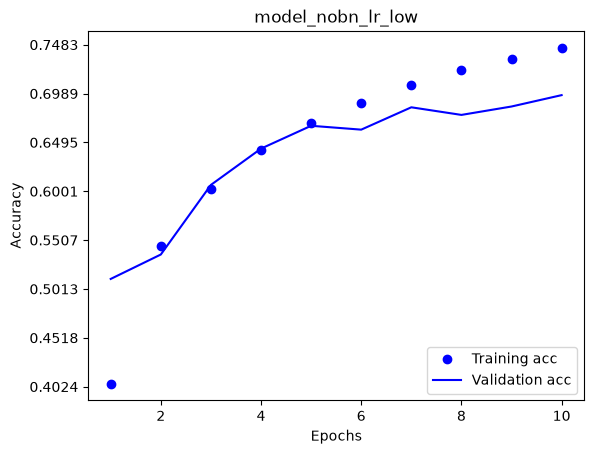

In [8]:
model_nobn_low = make_model_nobn()
hist_nobn_low = train_or_load(model_nobn_low, "model_nobn_lr_low", LR_LOW)

### WITH BATCH NORM - LR = 1e-3

 10%|█         | 1/10 [00:10<01:38, 10.92s/it]

Epoch 1/10 - loss: 1.2100 - accuracy: 0.5715 - val_loss: 1.0651 - val_accuracy: 0.6204


 20%|██        | 2/10 [00:19<01:16,  9.60s/it]

Epoch 2/10 - loss: 0.8754 - accuracy: 0.6934 - val_loss: 0.9075 - val_accuracy: 0.6817


 30%|███       | 3/10 [00:28<01:05,  9.29s/it]

Epoch 3/10 - loss: 0.7522 - accuracy: 0.7385 - val_loss: 0.8818 - val_accuracy: 0.6864


... (10 outputs left out)

 90%|█████████ | 9/10 [01:23<00:09,  9.20s/it]

Epoch 9/10 - loss: 0.4142 - accuracy: 0.8540 - val_loss: 0.8146 - val_accuracy: 0.7346


100%|██████████| 10/10 [01:32<00:00,  9.22s/it]

Epoch 10/10 - loss: 0.3812 - accuracy: 0.8661 - val_loss: 0.7806 - val_accuracy: 0.7514


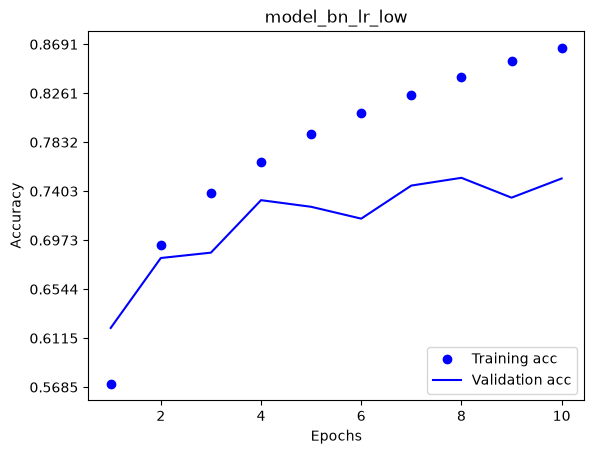

In [9]:
model_bn_low = make_model_bn()
hist_bn_low = train_or_load(model_bn_low, "model_bn_lr_low", LR_LOW)

### WITHOUT BATCH NORM - LR = 1e-2

 10%|█         | 1/10 [00:12<01:56, 12.96s/it]

Epoch 1/10 - loss: 1.8239 - accuracy: 0.3085 - val_loss: 1.6599 - val_accuracy: 0.3699


 20%|██        | 2/10 [00:23<01:33, 11.72s/it]

Epoch 2/10 - loss: 1.6636 - accuracy: 0.3750 - val_loss: 1.7098 - val_accuracy: 0.3654


 30%|███       | 3/10 [00:34<01:20, 11.44s/it]

Epoch 3/10 - loss: 1.6424 - accuracy: 0.3869 - val_loss: 1.6102 - val_accuracy: 0.3974


... (10 outputs left out)

 90%|█████████ | 9/10 [01:34<00:10, 10.02s/it]

Epoch 9/10 - loss: 1.6035 - accuracy: 0.4039 - val_loss: 1.6424 - val_accuracy: 0.3935


100%|██████████| 10/10 [01:46<00:00, 10.60s/it]

Epoch 10/10 - loss: 1.5973 - accuracy: 0.4064 - val_loss: 1.6268 - val_accuracy: 0.3942


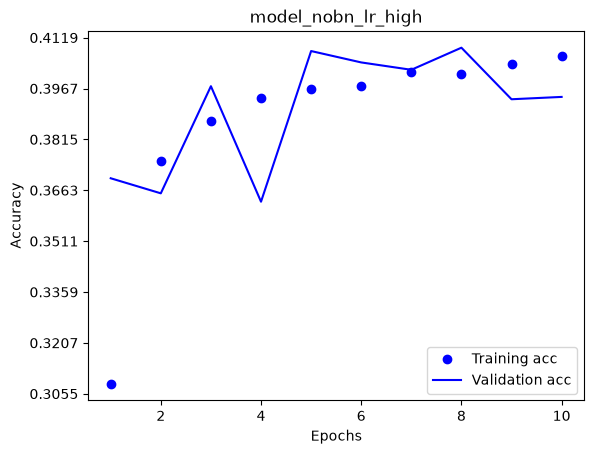

In [10]:
model_nobn_high = make_model_nobn()
hist_nobn_high = train_or_load(model_nobn_high, "model_nobn_lr_high", LR_HIGH)

### WITH BATCH NORM - LR = 1e-2

 10%|█         | 1/10 [00:10<01:34, 10.49s/it]

Epoch 1/10 - loss: 1.3027 - accuracy: 0.5321 - val_loss: 1.1688 - val_accuracy: 0.5973


 20%|██        | 2/10 [00:19<01:16,  9.51s/it]

Epoch 2/10 - loss: 0.9671 - accuracy: 0.6587 - val_loss: 0.9039 - val_accuracy: 0.6845


 30%|███       | 3/10 [00:28<01:05,  9.29s/it]

Epoch 3/10 - loss: 0.8348 - accuracy: 0.7091 - val_loss: 0.9551 - val_accuracy: 0.6630


... (10 outputs left out)

 90%|█████████ | 9/10 [01:23<00:09,  9.21s/it]

Epoch 9/10 - loss: 0.4867 - accuracy: 0.8284 - val_loss: 0.7899 - val_accuracy: 0.7484


100%|██████████| 10/10 [01:32<00:00,  9.29s/it]

Epoch 10/10 - loss: 0.4547 - accuracy: 0.8387 - val_loss: 0.8153 - val_accuracy: 0.7487


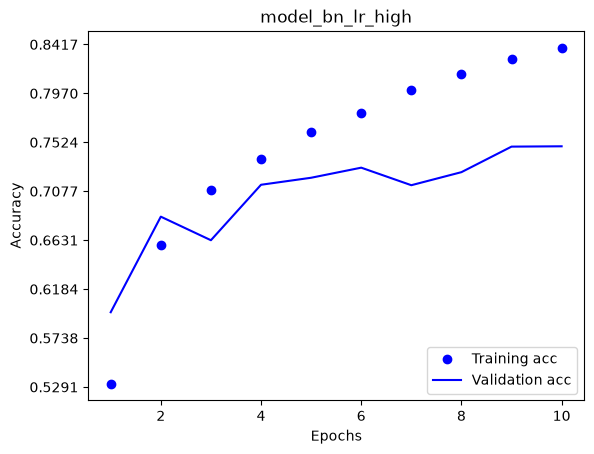

In [11]:
model_bn_high = make_model_bn()
hist_bn_high = train_or_load(model_bn_high, "model_bn_lr_high", LR_HIGH)

# Results

In [12]:
x_test_t = torch.as_tensor(x_test, dtype=torch.float32)
y_test_t = torch.as_tensor(y_test, dtype=torch.long)

models = {
    'NO BN, LR 1e-3': (model_nobn_low, hist_nobn_low),
    'BN,    LR 1e-3': (model_bn_low, hist_bn_low),
    'NO BN, LR 1e-2': (model_nobn_high, hist_nobn_high),
    'BN,    LR 1e-2': (model_bn_high, hist_bn_high),
}

print(f"{'':<16}{'LOSS':>8}{'ACCURACY':>10}{'VAL ACC EPOCA 1':>18}")
for label, (model, hist) in models.items():
    loss, acc = evaluate(model, x_test_t, y_test_t, loss_fn, device=device)
    print(f"{label:<16}{loss:>8.3f}{acc:>10.3f}{hist['val_accuracy'][0]:>18.3f}")

                    LOSS  ACCURACY   VAL ACC EPOCA 1
NO BN, LR 1e-3     0.876     0.697             0.511
BN,    LR 1e-3     0.781     0.751             0.620
NO BN, LR 1e-2     1.627     0.394             0.370
BN,    LR 1e-2     0.815     0.749             0.597
